In [1]:
# imports
import numpy as np
import matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
import torch
from pathlib import Path
import re
from skimage import io


%load_ext autoreload
%autoreload 2

In [13]:
# Make color palette for all groups we'll come across
tmp_patterns = ["small-intestine","random", "intranuclear", "nuclear-edge", "extranuclear", "foci", "protrusion", "cell-edge", "perinuclear", 
                         "pericellular","pattern"]
def get_cmap(n, name='tab10'):
    ##Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    ##RGB color; the keyword argument name must be a standard mpl colormap name.
    return plt.cm.get_cmap(name, n)

global_cmap = get_cmap(len(tmp_patterns))
# cmap = get_cmap(len(adata.obs["pattern"].unique()), name="tab10")
palette = {}
for i, el in enumerate(tmp_patterns):
    palette[el] =  global_cmap(i)

In [4]:
# tmp pointer to acutal data, remove before committing
simulation_dir = Path("/mnt/data/david/simulated_cells/templates/")
data_dir = Path("/mnt/data/david/subcellspace_data/simulated_data/")

In [7]:
# Make sure seed is the same at all times, in all packages that use it
seed = 101
torch.manual_seed(seed)
import random
random.seed(seed)
np.random.seed(seed)

In [8]:
# boilerplate for saving plots
from src.plotting import saveAFigure
out_dir = Path("/path/to/wherever/")

In [ ]:
simulation_dir = Path("/path/to/output/of/simulations/") # output of training_subcellspace/create_simulations/

In [ ]:
data_dir = Path("path/to/data/dir/")

In [27]:
subcellspace = torch.load("/home/luna.kuleuven.be/u0147891/SubCellSpace/SubCellSpace")

## Util functions

In [23]:
from skimage.transform import rotate

base_cell_mask_dir = Path("/mnt/data/david/simulated_cells/with_dapi/even_less_spots/coordinate_parsed_with_coords/cell_mask_zoomed/")
def plotFullDataPoint(adata, ax=None):
    assert len(adata) == 1
    img = io.imread(adata.obs["original_image_paths"].iloc[0])
    dapi = io.imread(adata.obs["corresponding_dapis"].iloc[0])
    try:
        # cell = glob(str(base_cell_mask_dir / f"*cellID{adata.obs['cell_id'].iloc[0]}_*"))[0]
        cell = base_cell_mask_dir  / Path( adata.obs["corresponding_dapis"].iloc[0]).name.replace("DAPI", "cell-mask")
        cell = io.imread(cell)
#         print(adata.obs["original_image_paths"].iloc[0], cell)
    except:
        cell = np.zeros((dapi.shape))
        print("No cell found")
    if ax is None:
        fig, ax = plt.subplots(1,1)
        
    ax.imshow(img + ((dapi > 0) / 16) + ((cell > 0) / 16))

In [25]:
def decodeSubcellEmbedding(embedding, model):
    changed_tensor = torch.from_numpy(embedding).float()
    decoded_tensor = model["cvae"].decode(changed_tensor.to(model["device"]))
    reconstruction = decoded_tensor[0,0, :, :].cpu().detach().numpy()
    return reconstruction

In [68]:
from skimage.filters import gaussian

def plotAllDataFromLeidenCluster(full_adata, leiden_cluster, ax, leiden_key = "leiden",cell_id = None, model = None):
    combined_data_tmp = full_adata[full_adata.obs[leiden_key] == leiden_cluster]
    # If we don't wanna decode, we look at original data
    if model is None:
        # if a cell id is given, we just wanna plot a random observation in a specific cell from this leiden cluster
        if cell_id is not None:
            combined_data_tmp = combined_data_tmp[combined_data_tmp.obs["cell_id"] == str(cell_id)]
            random_gene_in_this_cell = combined_data_tmp[0]
            # ur mom is done
            plotFullDataPoint(single_cell_adata[getXYOfSingleCell(combined_data_tmp, 0)], ax=ax)
            ax.set_title(combined_data_tmp.obs["gene_name"].iloc[0] + f", {leiden_cluster}")
        # if neither model nor cell are given, we just take all input
        else:
            images = []
            for tmp_row in combined_data_tmp:
                input_img = createInputImage(single_cell_adata[tmp_row.obs["original_obs_index"].iloc[0], tmp_row.obs["original_gene_index"].iloc[0]])
                images.append(input_img)
            mean_image = np.mean(np.array(images), axis=0)
            ax.imshow(mean_image)
            ax.set_title(leiden_cluster)
    
    else:
        average_embedding = np.mean(combined_data_tmp.X, axis=0)
        average_decoding = decodeSubcellEmbedding(average_embedding, subcellspace)
        ax.imshow(average_decoding)
        ax.set_title(leiden_cluster)
        ax.axis('off')

# Figure 1B

NameError: name 'simfish' is not defined

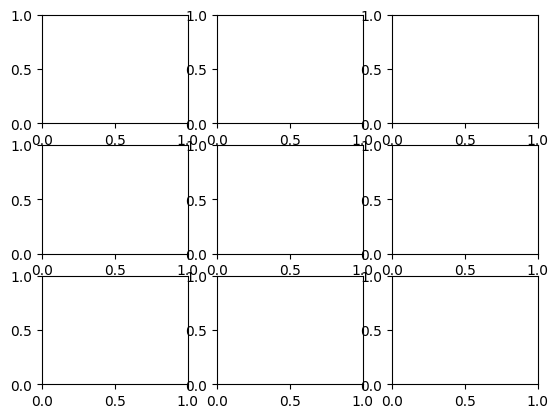

In [8]:
from training_subcellspace.create_simulations.createGeneExpressionPatterns_parallel import resizePointWithTransform, createGeneExpressionImg
from skimage.transform import resize

proportion_pattern = 0.9
pattern_strings = ["random" , "foci", "intranuclear", "extranuclear", "nuclear_edge", "perinuclear", "cell_edge", "pericellular", "protrusion"]
fig, axs = plt.subplots(3,3)
axs = axs.flatten()
i=25

for patt_counter, pattern in  enumerate( pattern_strings ) :
    images_for_this_pattern = []
    for counter in range(100):
        n_spots = random.randint(10, 100)
        try:
            instance_coord = simfish.simulate_localization_pattern(str(simulation_dir), i_cell = i, n_spots = n_spots, pattern = pattern, proportion_pattern = proportion_pattern)
        except ValueError as e:
            print(e)
            break
        rows = instance_coord["rna_coord"][:,1]
        cols = instance_coord["rna_coord"][:,2]
        zoom_factors = 100 / instance_coord["nuc_mask"].shape[0], 100 / instance_coord["nuc_mask"].shape[1]
        new_nuc = resize(instance_coord["nuc_mask"], (100,100))
        new_cell = resize(instance_coord["cell_mask"], (100,100))
        new_rows = []
        new_cols = []

        for point in zip(rows, cols):
            new_point = resizePointWithTransform(point, zoom_factors)
            new_rows.append(new_point[0])
            new_cols.append(new_point[1])

        ge_image = createGeneExpressionImg(new_rows, new_cols, (100,100))
        ge_image_gauss = gaussian(ge_image, 1)

        images_for_this_pattern.append(ge_image_gauss)

    tmp_pattern = pattern.replace("_", "-")
    if not images_for_this_pattern:
        continue

    images_for_this_pattern = np.array(images_for_this_pattern)

    sm = np.sum(images_for_this_pattern, axis=0)
    axs[patt_counter].imshow(sm)
    axs[patt_counter].axis("off")
    axs[patt_counter].set_title(tmp_pattern)


# Figure 2A–B

In [15]:
sim_adata = ad.read_h5ad("/mnt/data/david/simulated_cells/with_dapi/even_less_spots/adata_unbalanced_traintestsplit_with_umap.h5ad")

In [20]:
val_adata = sim_adata[sim_adata.obs["train_or_val"] == "val"]

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


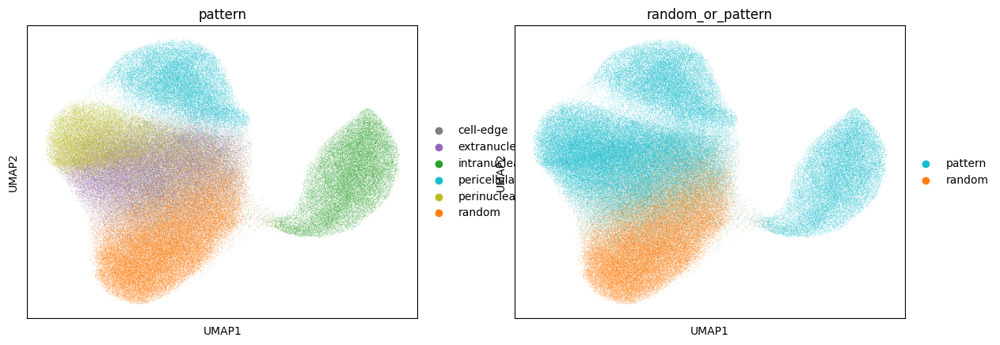

In [17]:
sc.pl.umap(sim_adata, color=["pattern", "random_or_pattern"], palette = palette)

# Figure 1C

In [21]:
seed_used_for_paper = 368

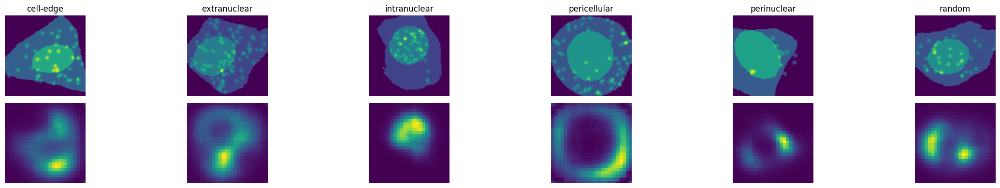

In [29]:
import matplotlib.pyplot as plt

patterns = val_adata.obs["pattern"].unique()  # all unique labels
nr_images = len(patterns)

fig, axs = plt.subplots(2, nr_images, figsize=(4*nr_images, 4))

random.seed(seed_used_for_paper)

# if only 1 pattern, axs is not an array
if nr_images == 1:
    axs = [axs]
idxs = []
for i, pattern in enumerate(patterns):
    # pick one datapoint with this pattern (you can change to .sample(n=...) for more)
    idx = val_adata.obs[val_adata.obs["pattern"] == pattern].sample(n=1).index[0]
    idxs.append(idx)
    plotFullDataPoint(val_adata[idx], ax=axs[0, i])
    axs[0, i].set_title(pattern)
    axs[0, i].axis("off")
    
for i, random_nr in enumerate(idxs):        
    decoded = decodeSubcellEmbedding(val_adata[random_nr].X, subcellspace)
    axs[1, i].imshow(decoded)
    axs[1,i].axis("off")
    
plt.tight_layout()



# Fig 2C–E

In [31]:
# Sanity check that train and val have stratified cellid
assert len(set(sim_adata[sim_adata.obs["train_or_val"] == "val"].obs["cell_id"].unique()).intersection(set(sim_adata[sim_adata.obs["train_or_val"] == "train"].obs["cell_id"].unique()))) == 0

In [43]:
sim_adata.obs["rotation_interval_45"] =  pd.cut(sim_adata.obs['rotation'], bins=[0, 45, 90, 135, 180, 225, 270, 315, float('Inf')], labels=["0-45", "45-90", "90-135", "135-180", "180-225", "225-270", "270-315", "315+"], include_lowest=True)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


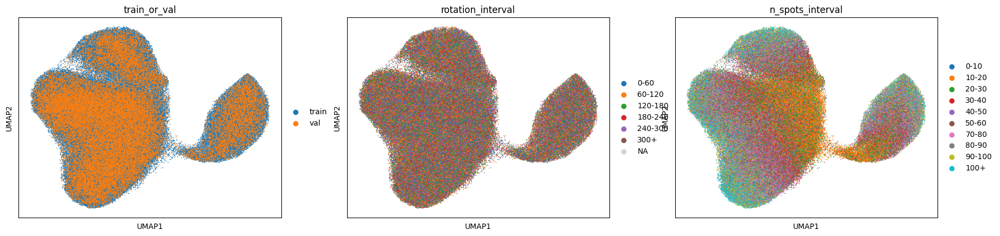

In [36]:
fig = sc.pl.umap(sim_adata, color=["train_or_val", "rotation_interval_45", "n_spots_interval"], s=5, return_fig=True)

In [40]:
most_occuring_cell = '95'

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


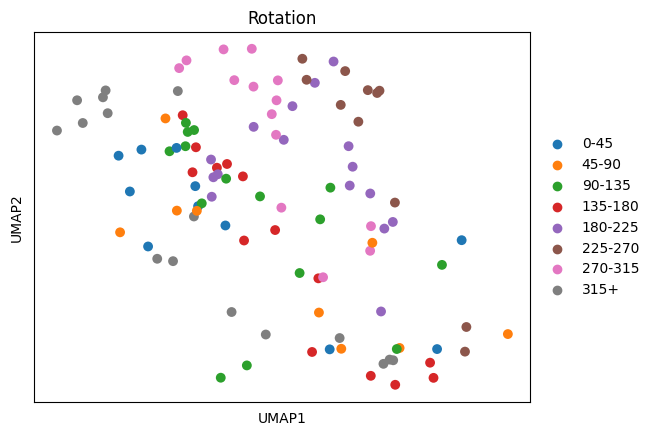

In [45]:
sc.pl.umap(sim_adata[(sim_adata.obs["cell_id"] == most_occuring_cell) & (sim_adata.obs["pattern"] == "pericellular")], color=["rotation_interval_45"], legend_fontsize=10, title="Rotation",  s=200, return_fig = False)


# Fig 2F

In [46]:
# Data
sim_adata = ad.read_h5ad(data_dir / "simulated_data" / "adata_all_simulated_data.h5ad")

In [48]:
sc.pp.neighbors(sim_adata, n_neighbors=25)

In [49]:
sc.tl.umap(sim_adata)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


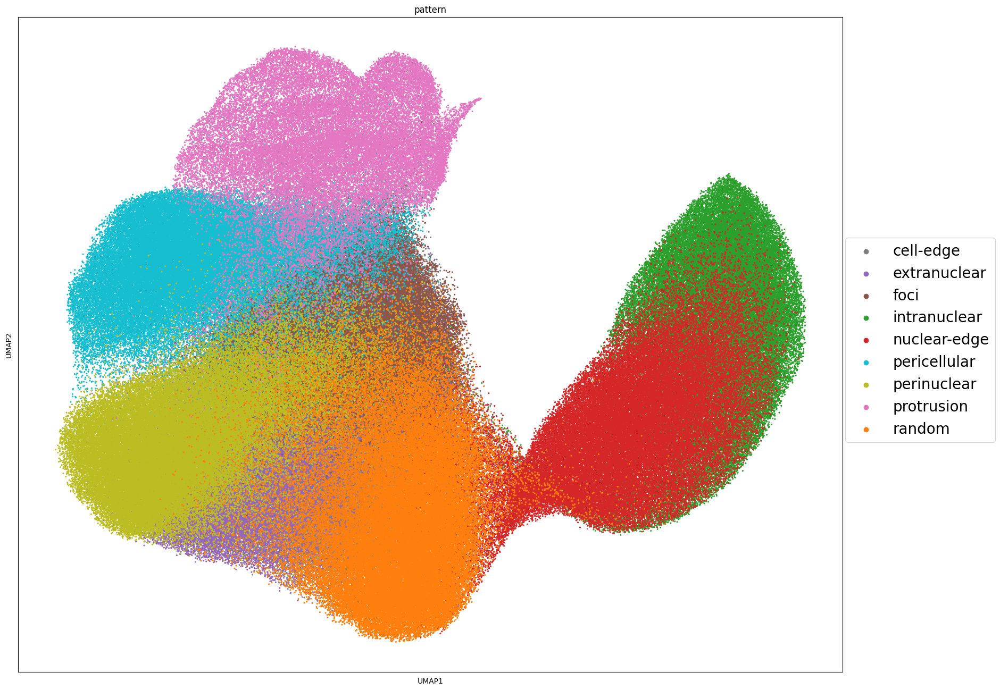

In [70]:
plt.rcParams["figure.figsize"] = [20,16]
# sizes = [40 if el != 'cell-edge' else 100 for el in sim_adata.obs["pattern"]]
# alpha_list = [1 if patt == 'cell-edge' else 0.1 for patt in sim_adata.obs["pattern"]]
fig = sc.pl.umap(sim_adata, color="pattern", palette = palette, s= 20, return_fig=True)
handles, labels = fig.gca().get_legend_handles_labels()
fig.gca().legend().remove()
fig.legend(handles, labels, fontsize = 20, markerscale=1, bbox_to_anchor=(1.05, 0.5), loc='center right')

# Fig 2G

In [71]:
single_cell_adata = ad.read_h5ad("/mnt/data/MERFISH/moor_data/merfish/ileum/parsed_adata/adata_subcell.h5ad")

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/aligned_mapping.py:54: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(


In [72]:
adata = ad.read_h5ad("/mnt/data/MERFISH/moor_data/merfish/ileum/parsed_adata/adata_subcell_embeddings_classified_and_subtype_and_leiden.h5ad")

In [73]:
import awkward as ak
def convertRecordToDf(record):
    awkward_list = ak.to_list(record)
    if all([value is None for value in awkward_list.values()]):
        return pd.DataFrame(columns=list(ak.to_list(adata.obsm["detected_transcripts"][x]).keys()))
    else:
        return pd.DataFrame.from_dict(awkward_list)

In [88]:
def plotFullDataPoint(adata, tile_nr = None, cell_id = None, gene = None, ax = None, color="red", size=None, row_coords = "subcell_row", col_coords= "subcell_col", return_fig=False):
#     adata_for_this_cell = adata[adata.obs["cell_id"] == cell_id]
    if cell_id is not None:
        adata_for_this_cell_gene = adata[(adata.obs["tile_nr"] == tile_nr) & (adata.obs["cell_id"] == cell_id), gene]
    else:
        adata_for_this_cell_gene = adata
        gene = adata_for_this_cell_gene.var_names[0]
        cell_id = adata_for_this_cell_gene.obs_names[0]
    # this function assumes you either pass an adata slice of len == 1, or that you pass identifiers that could slice it that way
    assert len(adata_for_this_cell_gene) == 1
    
    cell_mask_for_this_cell = (adata_for_this_cell_gene.obsm["cell_mask"][0].reshape(100,100) > 0) * 2
    dapi_mask_for_this_cell = adata_for_this_cell_gene.obsm["dapi_mask"][0].reshape(100,100) > 0
    
    tile_nr = str(adata_for_this_cell_gene.obs["tile_nr"][0])
    measured_df_for_this_tile = adata_for_this_cell_gene.uns["measured_df"][tile_nr]
    detected_transcripts_for_this_cell = convertRecordToDf(adata_for_this_cell_gene.obsm["detected_transcripts"][0])
    
    detected_transcripts_for_this_gene = detected_transcripts_for_this_cell[detected_transcripts_for_this_cell["gene"] == gene]
    
    assert adata_for_this_cell_gene.X == len(detected_transcripts_for_this_gene)
    
    if ax is None:
        fig, ax = plt.subplots(1,1)
 
    ax.imshow(cell_mask_for_this_cell + dapi_mask_for_this_cell)
    if size is None:
        ax.scatter(detected_transcripts_for_this_gene[col_coords], detected_transcripts_for_this_gene[row_coords], color=color)
    else:
        ax.scatter(detected_transcripts_for_this_gene[col_coords], detected_transcripts_for_this_gene[row_coords], color=color, s=size)
       
    if return_fig:
        return fig
    
def getXYOfSingleCell(adata, slc):
    row = adata[slc]
    assert len(row) == 1
    return int(row.obs["original_cell_index"][0]), int(row.obs["original_gene_index"][0])
# # Find most expressed cell for viz purposes
# x, y = np.unravel_index(np.argmax(adata.X), adata.X.shape)

# plotFullDataPoint(adata[x, y])

In [89]:
adata.var_names = list(sim_adata.var_names)
adata.obs["pattern"] = "small-intestine"

In [76]:
combined_adata = ad.concat([adata, sim_adata], join="outer")

In [77]:
sc.tl.pca(combined_adata, svd_solver='arpack', n_comps = combined_adata.X.shape[1]-1)



In [78]:
n_neighbors = 25



In [79]:
sc.pp.neighbors(combined_adata, n_neighbors=n_neighbors, n_pcs=25)



In [80]:
sc.tl.umap(combined_adata)

In [81]:
sizes = [30 if el != 'small-intestine' else 200 for el in combined_adata.obs["pattern"]]

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


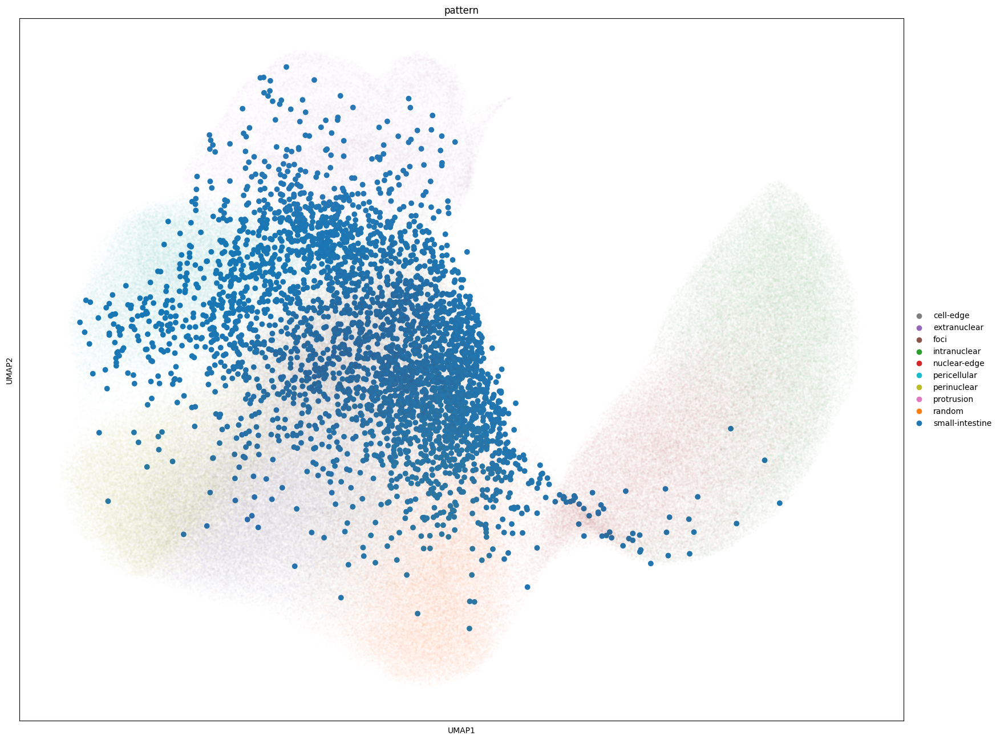

In [82]:
%matplotlib inline
alpha_list = [1 if patt == 'small-intestine' else 0.01 for patt in combined_adata.obs["pattern"]]
# sizes = [39 if patt == "foci" else 30 for patt in tmp_adata.obs["pattern"]]
sc.pl.umap(combined_adata, color="pattern", palette = palette, alpha=alpha_list, s=sizes)

In [83]:
clicked_points_df = pd.read_csv("./clicked_points_fig1.csv")

In [84]:
clicked_points_df = clicked_points_df[clicked_points_df["closest_pattern"] != "cell-edge"]

In [85]:
clicked_points_df

,closest_pattern,gene_name,point
0,intra,Gzma,"(11.743605488718138,1.681557905948658)"
1,random,Pigr,"(2.462155152877, -4.43427751607)"
2,perinuclear,Cyb5r3,"(-2.7735347801, -1.47859994)"
3,extranuclear,Pigr,"(-4.938047291312, 0.2687814868976304)"
4,pericellular,Aoc1,"(-7.2839339870, 3.559064336735)"
5,protrusion,Apob,"(-3.2721715, 11.143445115197913)"


In [86]:
from scipy import spatial
from ast import literal_eval
plt.rcParams["figure.figsize"] = [20,16]
def plotClickedImages(plot_adata, adata, clicked_points_df, size=2):
    '''
    All data argument is just so that we can plot just a subset, but find the closest label in the entire dataset
    '''
    #     global pos
    def findSecondClosestDot(adata, point, tree):
        closest_neighbor_index = tree.query([point], k=2)[1][0][0] # last indexing is which closest neighbor to take
        return closest_neighbor_index
        
    coord_list = []
    for row in adata.obsm["X_umap"]:
        coord_list.append(tuple(row))
    tree = spatial.KDTree(coord_list)
    
    global_fig, global_ax = plt.subplots(1,1)
    gene_fig, gene_axs = plt.subplots(2,3)
    gene_axs = gene_axs.flatten()
    for ax in gene_axs:
        ax.axis("off")
        
    sizes = [40 if el != 'small-intestine' else 150 for el in combined_adata.obs["pattern"]]
    alpha_list = [1 if patt == 'small-intestine' else 0.08 for patt in combined_adata.obs["pattern"]]
    
    sc.pl.umap(combined_adata, color="pattern", palette = palette, alpha=alpha_list, s=sizes, ax=global_ax, show=False)
        
    for i, tmp_row in enumerate(clicked_points_df.itertuples()):
#         pos = (event.xdata,event.ydata)
        pos = literal_eval(tmp_row.point)

        index = tree.query([pos])[1][0]
        global_ax.scatter(
            pos[0], pos[1],
            c="red",
            s=150,
            marker="o",
            edgecolor="black",
            zorder=10,
        )
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, index)], ax=gene_axs[i], size=100)
        gene_axs[i].set_title(f"{tmp_row.gene_name}")
        gene_axs[i].axis("off")
    return global_fig, gene_fig

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


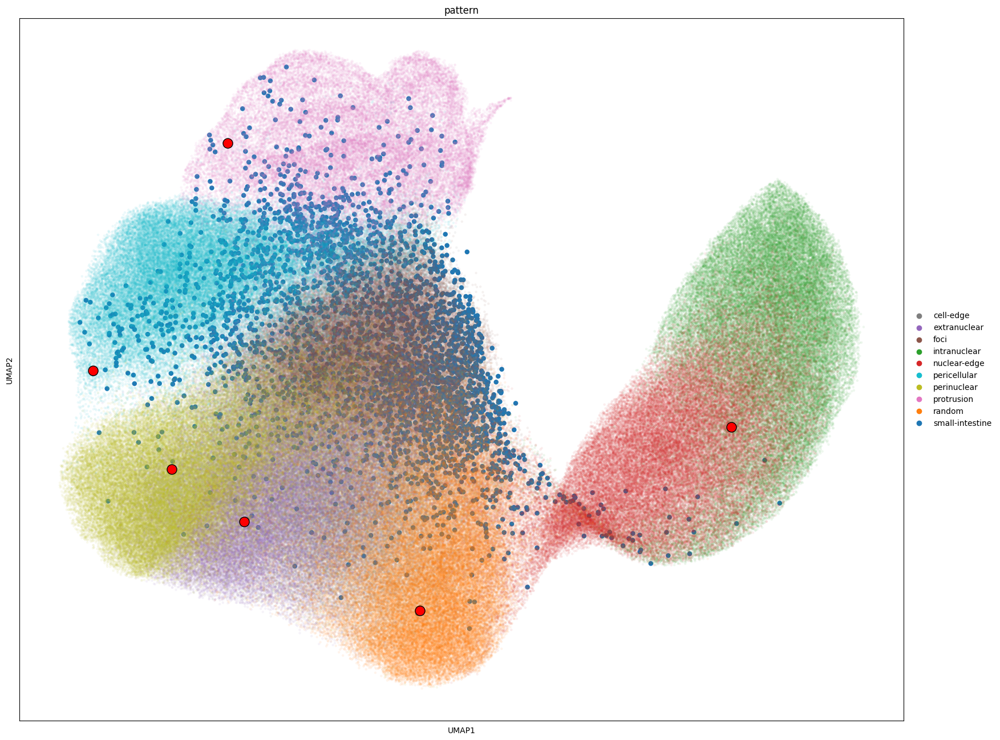

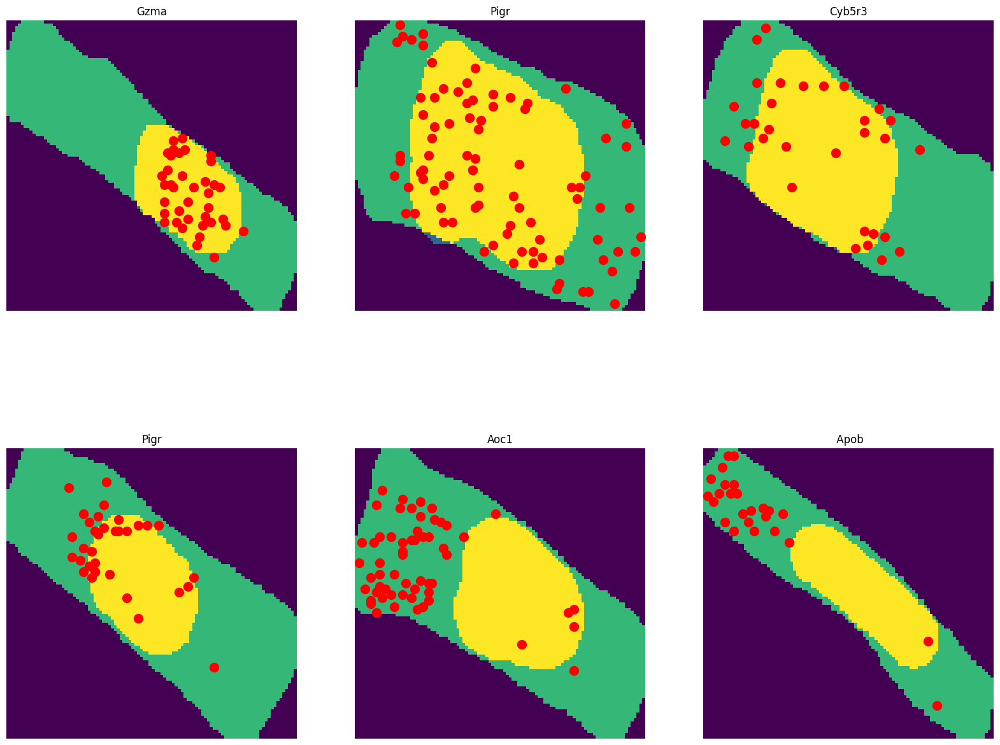

In [90]:
%matplotlib inline
global_fig, gene_fig = plotClickedImages(combined_adata, combined_adata[combined_adata.obs["pattern"] == "small-intestine"], clicked_points_df)

## Supp fig 4: Subcluster protrusion

In [57]:
protrusion_sim_adata = sim_adata[sim_adata.obs["pattern"] == "protrusion"]

In [58]:
adjacency = sc._utils._choose_graph(protrusion_sim_adata, neighbors_key="neighbors",obsp=None)

In [59]:
g = sc._utils.get_igraph_from_adjacency(adjacency)

In [60]:
res = 0.1

In [61]:
clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


/tmp/ipykernel_2950626/3850926258.py:1: DeprecationWarning: resolution_parameter keyword argument is deprecated, use resolution=... instead
  clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


In [62]:
protrusion_sim_adata.obs[f'leiden_igraph_res_{res}'] = pd.Series(clustering.membership,  index=protrusion_sim_adata.obs.index).astype('category')


/tmp/ipykernel_2950626/1477436878.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  protrusion_sim_adata.obs[f'leiden_igraph_res_{res}'] = pd.Series(clustering.membership,  index=protrusion_sim_adata.obs.index).astype('category')


/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


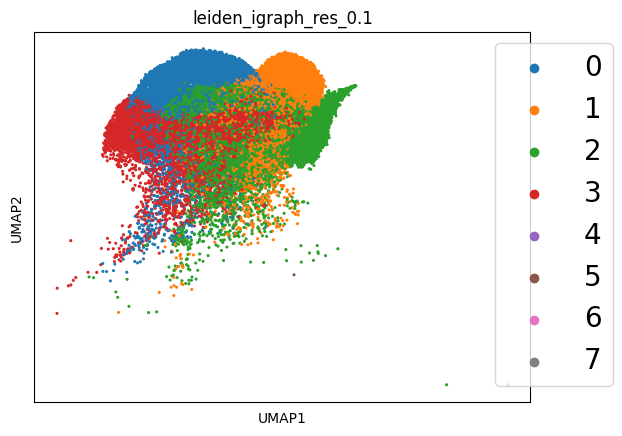

In [63]:
fig = sc.pl.umap(protrusion_sim_adata, color=f'leiden_igraph_res_{res}', legend_fontsize=10,  s=20,  return_fig = True, show=False)
handles, labels = fig.gca().get_legend_handles_labels()
fig.gca().legend().remove()
fig.legend(handles, labels, fontsize = 20, markerscale=1, bbox_to_anchor=(1.05, 0.5), loc='center right')

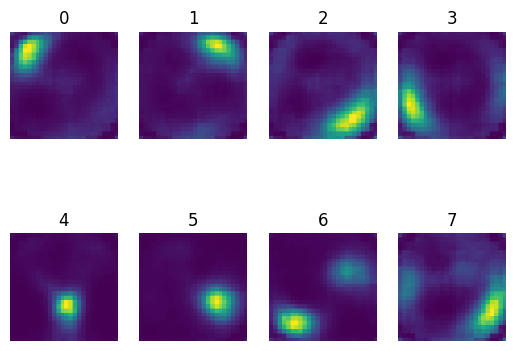

In [69]:
## Take mean of all cluster contents
# sc.pl.umap(sim_adata, color=[f"leiden_igraph_res_{res}", "pattern"], s=10)
nr_leiden_clusters = len(protrusion_sim_adata.obs[f'leiden_igraph_res_{res}'].unique())
fig, axs = plt.subplots(2,4)
axs = axs.flatten()
for leid in range(nr_leiden_clusters):
    plotAllDataFromLeidenCluster(
        full_adata = protrusion_sim_adata,
        leiden_cluster = leid,
        ax=  axs[leid],
        model=subcellspace,
        leiden_key = f"leiden_igraph_res_{res}"
    )

## Supplementary tables 1–2: what the latent separates and what it encodes

In [ ]:
# Both tables are computed on the validation split: cell templates none of the training saw
table_adata = ad.read_h5ad("/mnt/data/david/simulated_cells/with_dapi/even_less_spots/adata_unbalanced_traintestsplit_with_umap.h5ad")
table_adata = table_adata[table_adata.obs["train_or_val"] == "val"].copy()
# include_lowest, otherwise every rotation == 0 observation falls outside the bins and becomes NaN
table_adata.obs["rotation_interval_45"] =  pd.cut(table_adata.obs['rotation'].astype(float), bins=[0, 45, 90, 135, 180, 225, 270, 315, float('Inf')], labels=["0-45", "45-90", "90-135", "135-180", "180-225", "225-270", "270-315", "315+"], include_lowest=True)
assert table_adata.obs["rotation_interval_45"].notna().all()

tables_out_dir = Path("/mnt/data/david/reviews/tables/raw/")
tables_out_dir.mkdir(parents=True, exist_ok=True)

### Table 1: silhouette scores in the 15-dimensional latent space

In [ ]:
from src.benchmark_functions import compute_silhouette_per_label

# Computed on the latent the classifiers use, not on the 2D UMAP projection
silhouette_rows = []
for key in ["pattern", "n_spots_interval", "rotation_interval_45", "cell_id"]:
    score, per_label = compute_silhouette_per_label(table_adata, obs_key=key, use_rep="latent")
    silhouette_rows.append({"key": key, "subkey": "n/a", "score": score})
    if key == "pattern":
        for pattern, pattern_score in sorted(per_label.items()):
            silhouette_rows.append({"key": key, "subkey": pattern, "score": pattern_score})
table1 = pd.DataFrame(silhouette_rows)
table1.to_csv(tables_out_dir / "table1_silhouette_latent.csv", index=False)
table1

### Table 2: can a random forest predict metadata from the latent

In [ ]:
from src.benchmark_functions import kappa_probe

latent = table_adata.obsm["latent"]
cell_ids = table_adata.obs["cell_id"].astype(str).values
random_class = np.random.RandomState(seed).randint(0, 9, table_adata.n_obs) # a random 9-category label

# Folds are grouped by cell, so the forest is always tested on unseen cells. The exception is cell_id itself:
# grouping on the label being predicted makes kappa 0 by construction, so it is read against its chance level
table2_targets = [
    ("pattern", table_adata.obs["pattern"].astype(str).values, cell_ids),
    ("random_class", random_class, cell_ids),
    ("rotation_interval", table_adata.obs["rotation_interval_45"].astype(str).values, cell_ids),
    ("cell_id", cell_ids, None),
    ("n_spots_interval", table_adata.obs["n_spots_interval"].astype(str).values, cell_ids),
]
kappa_rows = []
for name, labels, groups in table2_targets:
    kappas = kappa_probe(latent, labels, groups=groups, seed=seed)
    chance_kappas = kappa_probe(latent, labels, groups=groups, seed=seed, shuffle_labels=True)
    kappa_rows.append({"metadata": name, "folds_grouped_by_cell": groups is not None, "n_folds": len(kappas),
                       "kappa_mean": np.mean(kappas), "kappa_sd": np.std(kappas, ddof=1),
                       "chance_kappa_mean": np.mean(chance_kappas), "chance_kappa_sd": np.std(chance_kappas, ddof=1)})
table2 = pd.DataFrame(kappa_rows)
table2.to_csv(tables_out_dir / "table2_metadata_kappa.csv", index=False)
table2

## Supp fig. 6: Perturb dapi to see what happens to the embedding

In [126]:
def make_fake_pattern_col_to_draw_dots(adata, index_list):
    fake_pattern_col = [pattern if i not in index_list else "this guy" for i, pattern in enumerate(adata.obs["pattern"])]
    adata.obs['fake_pattern_col'] = fake_pattern_col
    return adata

def plot_exactly_one_row_very_clearly(adata, index_list):
    adata = make_fake_pattern_col_to_draw_dots(adata, index_list)
    size_list = [100 if el == "this guy" else 1  for el in adata.obs['fake_pattern_col']]
    alpha_list = [1 if el == "this guy" else 0.1  for el in adata.obs['fake_pattern_col']]

    sc.pl.umap(adata, color="fake_pattern_col", alpha = alpha_list, s=size_list)

from skimage.transform import rotate
def perturb_nucleus(tmp_row, subcellspace, angle=180):
#     fig, axs = plt.subplots(2,2)
    img = io.imread(tmp_row.original_image_paths)
    dapi = io.imread(tmp_row.corresponding_dapis)
#     axs[0, 0].imshow(img + ((dapi > 0) / 8))
    

    # now rotate
    rotated_dapi = rotate(dapi, angle)
#     rotated_dapi = np.eye(100)
#     axs[1, 0].imshow(img + ((rotated_dapi > 0) / 8))

    gene_expression = subcellspace["cvae"].prepare_new_input(img)
#     dapi_prepared = subcellspace["cvae"].prepare_new_input(dapi)
    rotated_dapi_prepared = subcellspace["cvae"].prepare_new_input(rotated_dapi)

#     input_img = torch.cat((gene_expression, dapi_prepared), dim=1)
#     input_img = gene_expression
    morphed_input_img = torch.cat((gene_expression, rotated_dapi_prepared), dim=1)
    subcellspace["cvae"].to(subcellspace['device'])

#     input_img = input_img.to(subcellspace['device'])
    morphed_input_img = morphed_input_img.to(subcellspace['device'])

#     reconstruction_original, _, _ = subcellspace['cvae'].forward(input_img)
#     axs[0,1].imshow(np.array(reconstruction_original[0,0,:,:].detach().to("cpu")))

#     reconstruction_morphed, _, _ = subcellspace['cvae'].forward(morphed_input_img)
#     axs[1,1].imshow(np.array(reconstruction_morphed[0,0,:,:].detach().to("cpu")))
    embedding, _, _ = subcellspace['cvae'].embed(morphed_input_img)

#     changed_tensor = embedding.float()
#     decoded_tensor = subcellspace["cvae"].decode(changed_tensor.to(subcellspace["device"]))
#     reconstruction = decoded_tensor[0,0, :, :].cpu().detach().numpy()
#     axs[1,1].imshow(reconstruction)
#     plt.show()

    return embedding.cpu().detach().numpy()




In [127]:
seed_used_for_paper = 101

new_layer = np.zeros((adata.shape))
for i, tmp_row in tqdm(enumerate(adata.obs.itertuples())):
    rotation_angle = random.randint(1,361)
    embedding = perturb_nucleus(tmp_row, subcellspace=subcellspace, angle=rotation_angle)
    new_layer[i, :] = embedding

220687it [09:59, 368.15it/s]


In [128]:
adata.layers["perturbed_subcell_embedding"] = new_layer
# adata.layers["subcell_embedding"] = adata.X
adata.X = adata.layers["perturbed_subcell_embedding"]

In [129]:
sc.tl.pca(adata, svd_solver='arpack', n_comps = adata.X.shape[1]-1)



In [130]:
n_neighbors = 25



In [131]:
sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=25)



In [132]:
sc.tl.umap(adata)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


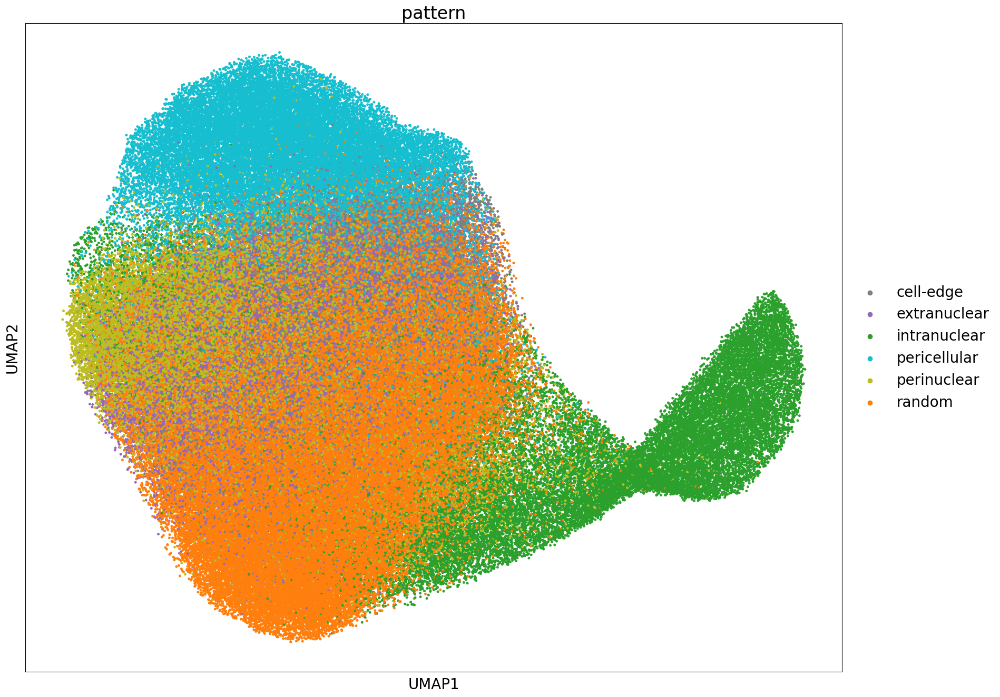

In [133]:
fig = sc.pl.umap(adata, color="pattern", s=50, palette = palette)

In [82]:
adata[adata.obs["train_or_val"] == "val"]

View of AnnData object with n_obs × n_vars = 44706 × 15
    obs: 'pattern', 'random_or_pattern', 'n_spots', 'n_spots_interval', 'prop', 'cell_id', 'genes', 'rotation', 'rotation_interval', 'corresponding_dapis', 'original_image_paths', 'train_or_val'
    uns: 'test_cellIDs', 'train_cellIDs', 'pca', 'neighbors', 'umap', 'pattern_colors'
    obsm: 'latent', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'perturbed_subcell_embedding', 'subcell_embedding'
    obsp: 'distances', 'connectivities'

In [134]:
from src.benchmark_functions import benchmark_classify_patterns
adata.X = adata.layers["perturbed_subcell_embedding"]
benchmark_classify_patterns(adata[adata.obs["train_or_val"] == "val"], list(adata[adata.obs["train_or_val"] == "val"].obs["pattern"]))

Accuracy:  0.703
Kappa:    0.633
F1 (weighted): 0.695
Recall (weighted): 0.703
Precision (weighted): 0.694
F1 per class:
  cell-edge: 0.571
  extranuclear: 0.400
  intranuclear: 0.891
  pericellular: 0.892
  perinuclear: 0.644
  random: 0.732


{'accuracy': 0.7030823603095782,
 'kappa': 0.6328326900971752,
 'f1_weighted': 0.6950464110721625,
 'recall_weighted': 0.7030823603095782,
 'precision_weighted': 0.6943936751464186,
 'f1_per_class': {'cell-edge': 0.5712708924629455,
  'extranuclear': 0.400259547645532,
  'intranuclear': 0.8905283198476914,
  'pericellular': 0.8921456377375774,
  'perinuclear': 0.6443684895833334,
  'random': 0.7324387189121488}}

In [135]:
adata.X = adata.layers["subcell_embedding"]
benchmark_classify_patterns(adata[adata.obs["train_or_val"] == "val"], list(adata[adata.obs["train_or_val"] == "val"].obs["pattern"]))

Accuracy:  0.702
Kappa:    0.631
F1 (weighted): 0.694
Recall (weighted): 0.702
Precision (weighted): 0.693
F1 per class:
  cell-edge: 0.569
  extranuclear: 0.404
  intranuclear: 0.888
  pericellular: 0.892
  perinuclear: 0.638
  random: 0.733


{'accuracy': 0.7019639422001521,
 'kappa': 0.6312741194159956,
 'f1_weighted': 0.6940885601268574,
 'recall_weighted': 0.7019639422001521,
 'precision_weighted': 0.6934353752072673,
 'f1_per_class': {'cell-edge': 0.5689696774712459,
  'extranuclear': 0.4044412085911904,
  'intranuclear': 0.8876012065407207,
  'pericellular': 0.8921038605040736,
  'perinuclear': 0.6380639868744873,
  'random': 0.7328108300676879}}

In [199]:
saveAFigure(fig, "unseen_sim_data_umap", rasterize=True, out_dir=technical_out_dir)